# RetailMind AI — Day 10: forecasting 4 weeks ahead with Seq2Seq and attention

Day 9 predicted one day. To plan stock we need the next 28 days. This notebook compares rolling the Day 9 model forward with a **Seq2Seq** model (an encoder that reads 8 weeks of history, a decoder that writes 4 weeks), with and without **attention**.

**The sales are made up** (the real Rossmann file needs a Kaggle account). Training takes about 3 minutes, so this notebook **reads the saved results** from `python -m src.train_day10`.

In [1]:
# Work from the project root so the `src` package can be imported
import os, sys
ROOT = os.path.abspath("..") if os.path.basename(os.getcwd()) == "notebooks" else os.getcwd()
os.chdir(ROOT)
sys.path.insert(0, ROOT)
print("project folder:", os.path.basename(ROOT))

project folder: day3-4


## 1. The windows: 56 days in, 28 days out

In [2]:
from src.demand_data import load_sales, daily_table, split_windows
from src.train_day10 import LOOKBACK, HORIZON

table, source = load_sales()
wide = daily_table(table)
train, validation, test = split_windows(wide, LOOKBACK, HORIZON)
print(source)
print("windows  train:", len(train[0]), "| validation:", len(validation[0]), "| test:", len(test[0]))
print("one window: X has", train[0].shape[1], "days, y has", train[1].shape[1], "days")

MADE-UP sales for 8 stores (the real Rossmann file was not found)
windows  train: 6120 | validation: 232 | test: 232
one window: X has 56 days, y has 28 days


## 2. The comparison (same test windows for every model; ONE run, seed 42)

In [3]:
import json
day10 = json.load(open("models/day10_results.json"))
print(f"{'Forecast of the next 28 days':<30}{'MAE':>8}{'RMSE':>8}    MAE week 1 / 2 / 3 / 4")
for name, s in day10["test_scores"].items():
    print(f"{name:<30}{s['mae']:>8}{s['rmse']:>8}    " + " / ".join(str(w) for w in s["mae_by_week"]))
print("\nrounds trained:", day10["rounds_trained"])
print("lowest MAE:", day10["lowest_mae"])

Forecast of the next 28 days       MAE    RMSE    MAE week 1 / 2 / 3 / 4
same weekday last week           474.2   671.6    661.3 / 278.4 / 677.5 / 279.4
same weekday 2 weeks ago         284.6   403.3    278.0 / 278.4 / 302.7 / 279.4
Day 9 LSTM rolled forward        287.0   384.9    253.5 / 277.2 / 311.9 / 305.4
Seq2Seq without attention        272.2   367.7    251.8 / 266.1 / 279.1 / 291.7
Seq2Seq with attention           286.0   386.6    264.1 / 279.3 / 302.2 / 298.4

rounds trained: {'Seq2Seq without attention': 88, 'Seq2Seq with attention': 70}
lowest MAE: Seq2Seq without attention


## 2b. One run is not enough: 5 random starts

A neural network starts from random numbers, so the same training gives different scores each time. The table above is one start (seed 42). `python -m src.check_day10_seeds` repeats the training from 5 different starts (about 10 minutes), and this notebook reads its saved results.

In [4]:
seeds = json.load(open("models/day10_seed_check.json"))
print("random starts:", seeds["seeds"])
for name, s in seeds["summary"].items():
    print(f"{name:<20} MAE per start {s['mae_per_seed']}  mean {s['mean']}  spread (std) {s['std']}")
print()
print("attention is better in", seeds["attention_better_in_runs"], "of", len(seeds["seeds"]), "runs; mean gap (with minus without):", seeds["mean_gap_with_minus_without"])
print("best simple baseline for comparison (same weekday 2 weeks ago):", day10["test_scores"]["same weekday 2 weeks ago"]["mae"])

random starts: [1, 2, 3, 4, 5]
without attention    MAE per start [287.1, 431.1, 298.9, 342.1, 645.8]  mean 401.0  spread (std) 132.4
with attention       MAE per start [397.9, 275.6, 308.9, 316.2, 277.5]  mean 315.2  spread (std) 44.4

attention is better in 3 of 5 runs; mean gap (with minus without): -85.8
best simple baseline for comparison (same weekday 2 weeks ago): 284.6


## 3. Attention: which past days did each forecast day look at?

Each row is a forecast day (day 1 at the top, day 28 at the bottom). Each column is a past day, from 56 days ago on the left to yesterday on the right. Bright means that past day got a lot of attention.

the 5 past days used most (days before the forecast starts): [31, 30, 32, 29, 33]
share of attention on 7, 14, 21 ... days back: 0.152 | an even spread would give: 0.143


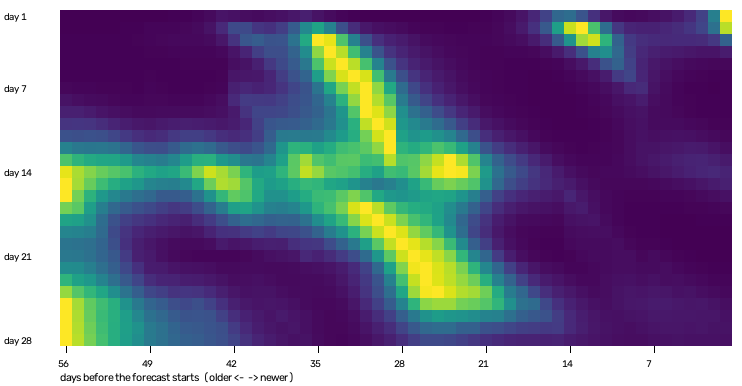

In [5]:
a = day10["attention"]
print("the 5 past days used most (days before the forecast starts):", a["most_used_days_back"])
print("share of attention on 7, 14, 21 ... days back:", a["share_on_weekly_lags"], "| an even spread would give:", a["share_if_even"])

from IPython.display import Image, display
display(Image("reports/day10_attention.png", width=640))

## 4. Use the demand module: the next 4 weeks

In [6]:
from src.demand_service import forecast_weeks

for store in list(wide.columns)[:3]:
    result = forecast_weeks(wide[store].to_numpy()[-LOOKBACK:])
    print("store", store, "weekly totals:", result["weekly_totals"])

store 1 weekly totals: [28561.5, 30281.4, 28694.6, 30605.9]
store 2 weekly totals: [29969.7, 26475.2, 28915.8, 25537.1]


store 3 weekly totals: [28232.6, 31522.1, 29161.2, 32055.1]


## 5. Conclusion

- **One run (seed 42) said attention did not help, but one run is not reliable.** Over 5 random starts, the network without attention ranged from 287 to 646 (average 401) and the one with attention from 276 to 398 (average 315). Attention was better on average and much more stable (3 of 5 runs). With only 5 runs that is suggestive, not proof, and the first version of this notebook drew the wrong conclusion from the single run.
- **Neither version reliably beats a trivial rule.** "Same weekday 2 weeks ago" scores 284.6, better than the average of both models. These made-up sales have a clean repeating pattern, so simple baselines are strong.
- **Rolling Day 9 forward gets worse with distance** (MAE 253.5 in week 1, 305.4 in week 4). The Seq2Seq models grow less.
- **The attention heatmap is not a clean explanation.** The bright band slides diagonally and the weekly lags (7, 14, 21 days back) get almost no extra attention (0.152 vs 0.143 for an even spread). Attention is over LSTM states that mix earlier days, so a bright cell does not prove one day mattered.
- The data is made up, so these scores show that the code works, not how it would do on real sales.